## Decoding SDO Image data generated from cFS

#### Importing Libraries

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
import math

torch.ops.load_library("./tiny_compressai/cpp_exts/ops/build/libtiny_compressai_cpp.so")
torch.classes.load_library("./tiny_compressai/cpp_exts/rans/build/libtiny_compressai_rans.so")

from tiny_compressai.models import NASACompressor

#### Defining paths and the preferred device to use

In [2]:
checkpoint_path = './model_checkpoint/sample_ckpt.ckpt'
data_path = './cfs_data/nn_manager00006001.tlm'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### Loading and formatting cFS generated data

In [4]:
data = np.fromfile(data_path,dtype='uint8', offset=140) #First 140 bytes are general file header

tensor_list = [];

chunk_size = 24016  #16 bytes: element header, 24000: element (last 2 bytes indicate element real size)

for i in range(0, len(data), chunk_size):
    data_row = data[i:i+chunk_size]
    elem_size = int.from_bytes(data_row[24014:24016], "little")
    bytes = data_row[16:elem_size+16]
    t = torch.Tensor(bytes).type(torch.uint8)
    tensor_list.append(t)

print(tensor_list)
print(len(tensor_list))

[tensor([ 38, 145,  71,  ..., 199, 140,   5], dtype=torch.uint8), tensor([163, 161, 231,  ...,  32, 160, 198], dtype=torch.uint8), tensor([ 97,  70,  73,  ...,  88, 245,  61], dtype=torch.uint8), tensor([ 23,  57,  38,  ...,  91,  89, 221], dtype=torch.uint8), tensor([109, 172, 109,  ...,  18, 234, 241], dtype=torch.uint8), tensor([ 11, 102,  73,  ..., 199, 140,   5], dtype=torch.uint8), tensor([113, 200, 164,  ..., 199, 140,   5], dtype=torch.uint8), tensor([146,  98, 224,  ..., 166, 199, 255], dtype=torch.uint8)]
8


#### Load original model with pretrained weights and testing model decompression

In [5]:
state_dict = torch.load(checkpoint_path, map_location=torch.device(device))['state_dict']
model = NASACompressor.from_state_dict(state_dict, strict=False).eval().to(device)
model.entropy_bottleneck.update()

t_size = torch.Size([32, 32])

with torch.no_grad():
    rec_out = model.decompress([tensor_list], t_size)

#### Visualize the reconstruction

torch.Size([8, 1, 512, 512])


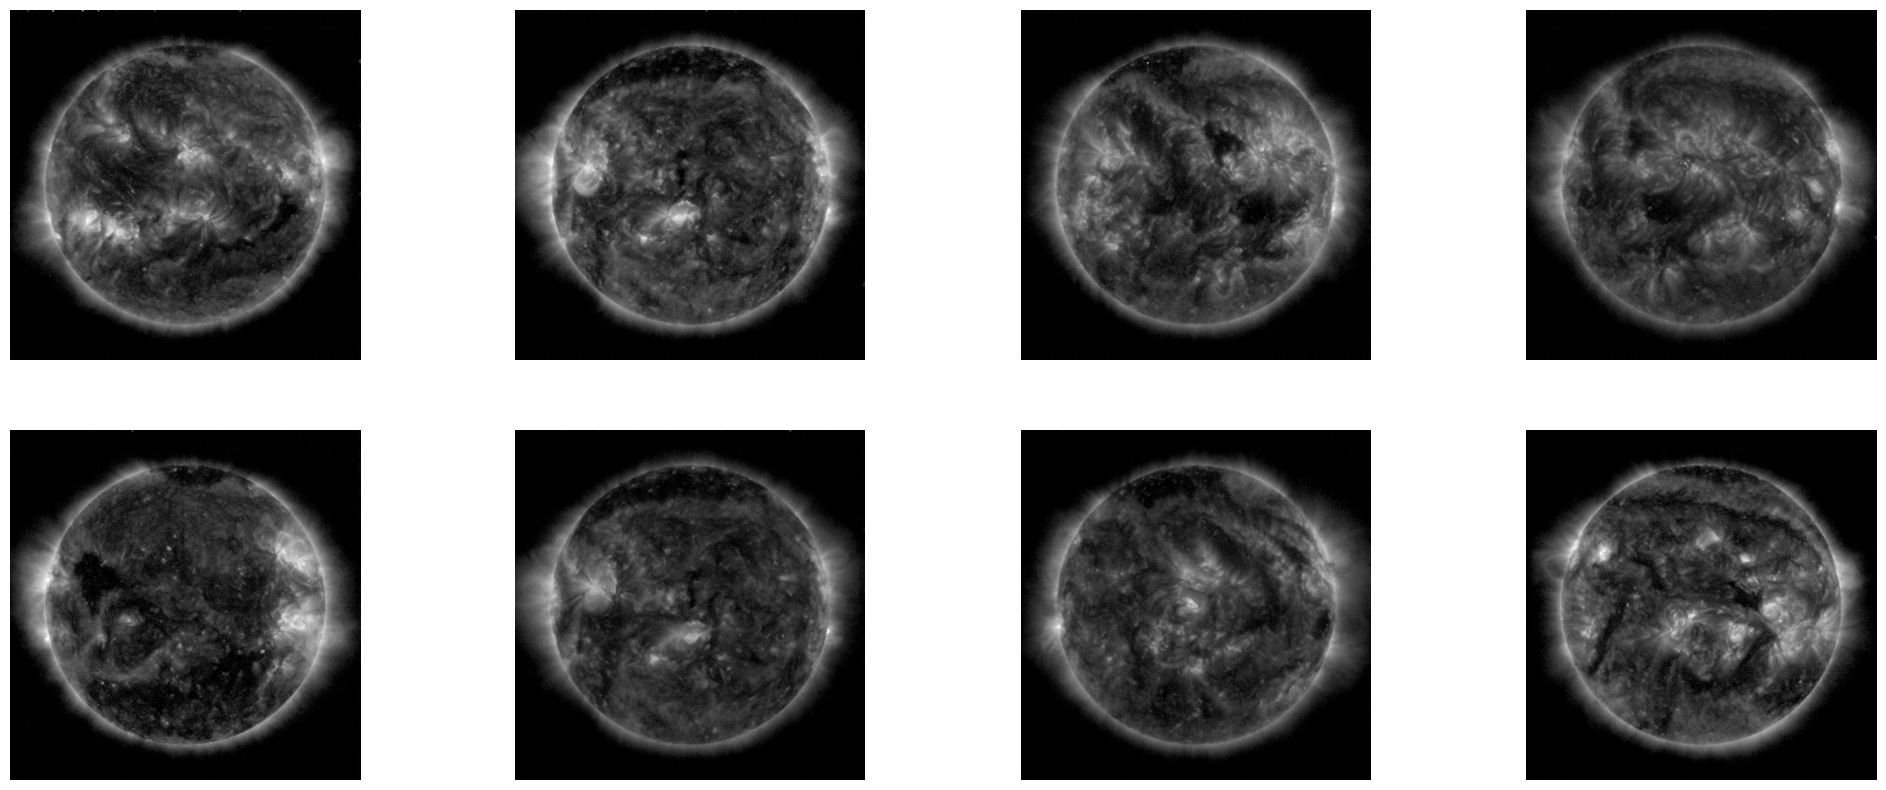

In [7]:
%matplotlib inline
fig, axes = plt.subplots(nrows=int(math.ceil(rec_out['x_hat'].size(0)/4)), ncols=4, figsize=(25,10))
print(rec_out['x_hat'].shape)

for row in axes:
    for ax in row:
        ax.axis('off')

for image, ax in zip(rec_out['x_hat'], axes.reshape(axes.size,1)):
    rec_image = transforms.ToPILImage()(image.squeeze().cpu())
    ax[0].imshow(rec_image, cmap='gray')


plt.show()